# Toxic Comment Detection Using a Bidirectional LSTM
### NLP Capstone Project | Multi-label Text Classification

**Objective:** Build a deep-learning system that identifies six types of toxic content in online comments using the Jigsaw Toxic Comment Classification dataset.

**Model:** PyTorch Bidirectional LSTM (BiLSTM)  
**Task:** Multi-label classification (one comment may have more than one label)  
**Primary environment:** Google Colab with GPU acceleration

> **Important:** This notebook is organized as a reproducible project report. Run the sections from top to bottom. The final test set is kept separate from model training and threshold selection. Outputs shown below are saved execution results from a previous run; rerun the notebook from the first cell to regenerate them.

### Project workflow

1. **Section 1:** Environment setup and reproducibility
2. **Section 2:** Connect Google Drive and load the dataset
3. **Section 3:** Exploratory data analysis
4. **Section 4:** Text cleaning and data preparation
5. **Section 5:** Create train, validation and test sets
6. **Section 6:** Build vocabulary and PyTorch DataLoaders
7. **Section 7:** Define the Bidirectional LSTM architecture
8. **Section 8:** Train the BiLSTM model
9. **Section 9:** Select per-label decision thresholds using validation data
10. **Section 10:** Evaluate the final model on the held-out test set
11. **Section 11:** Compare against an optional TF-IDF + Logistic Regression baseline
12. **Section 12:** Visualize training and test performance
13. **Section 12.1:** Inspect false-positive and false-negative predictions
14. **Section 13:** Save the trained model and project artifacts
15. **Section 14:** Load the saved model and predict new comments
16. **Section 15:** Present the conclusion, limitations and future scope


## SECTION 1 — Environment Setup and Reproducibility

This section imports the libraries used throughout the project, fixes random seeds so experiments are more repeatable, and selects a GPU when one is available. A GPU is recommended for faster BiLSTM training, but the notebook can also run on a CPU (more slowly).

In [1]:
# Install the small package used for multi-label stratified splitting.
!pip -q install iterative-stratification

import os
import re
import json
import time
import random
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, multilabel_confusion_matrix,
    average_precision_score, roc_auc_score, f1_score
)
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Make CUDA operations more repeatable where possible.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version : {torch.__version__}")
print(f"Selected device : {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU             : {torch.cuda.get_device_name(0)}")

PyTorch version : 2.11.0+cu130
Selected device : cuda
GPU             : Tesla T4


## SECTION 2 — Connect Google Drive and Load the Dataset

The original project uses the Jigsaw `train.csv` file stored in Google Drive. Mount Drive, set the dataset path, and load the complete dataset. If your file is stored in a different folder, update `DATA_PATH` below.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/DL_cyber_data/train.csv'

if not os.path.isfile(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Please upload train.csv to this location or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

LABEL_COLUMNS = [
    'toxic', 'severe_toxic', 'obscene',
    'threat', 'insult', 'identity_hate'
]
TEXT_COLUMN = 'comment_text'

required_columns = [TEXT_COLUMN] + LABEL_COLUMNS
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Keep only rows with valid text and normalize label types.
df = df.dropna(subset=[TEXT_COLUMN]).copy()
df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str)
df[LABEL_COLUMNS] = df[LABEL_COLUMNS].fillna(0).astype(np.float32)

print(f"Dataset shape : {df.shape}")
print(f"Text examples : {df[TEXT_COLUMN].notna().sum():,}")
print(f"Label columns : {LABEL_COLUMNS}")
display(df.head(3))

Mounted at /content/drive
Dataset shape : (159571, 8)
Text examples : 159,571
Label columns : ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0.0,0.0,0.0,0.0,0.0,0.0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0.0,0.0,0.0,0.0,0.0,0.0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0.0,0.0,0.0,0.0,0.0,0.0


## SECTION 3 — Exploratory Data Analysis (EDA)

Before training, inspect the number of examples in each class, the proportion of comments with at least one toxic label, and how many labels can apply to one comment. This matters because the dataset is strongly imbalanced: some labels occur much less often than others.

Total comments                 : 159,571
Comments with >= 1 toxic label : 16,225
Comments with no toxic labels  : 143,346


,Positive examples,Positive rate (%)
toxic,15294,9.584
severe_toxic,1595,1.000
obscene,8449,5.295
threat,478,0.300
insult,7877,4.936
identity_hate,1405,0.880


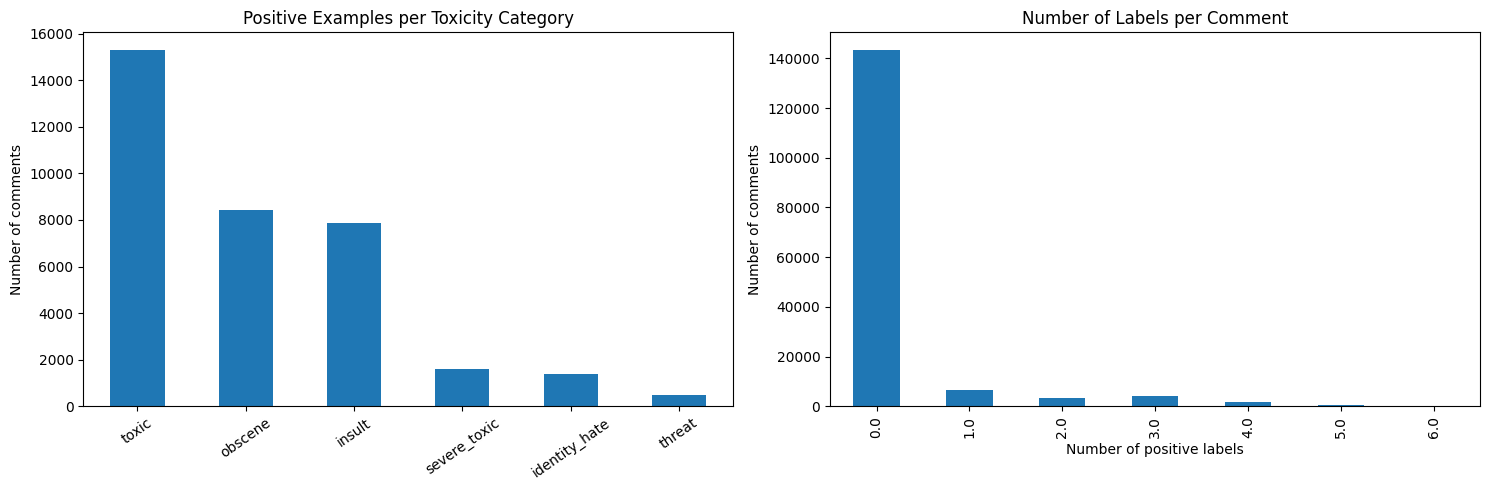

In [3]:
label_counts = df[LABEL_COLUMNS].sum().sort_values(ascending=False)
positive_comments = int((df[LABEL_COLUMNS].sum(axis=1) > 0).sum())
clean_comments = int((df[LABEL_COLUMNS].sum(axis=1) == 0).sum())
labels_per_comment = df[LABEL_COLUMNS].sum(axis=1).value_counts().sort_index()

summary = pd.DataFrame({
    'Positive examples': df[LABEL_COLUMNS].sum().astype(int),
    'Positive rate (%)': (df[LABEL_COLUMNS].mean() * 100).round(3)
})
print(f"Total comments                 : {len(df):,}")
print(f"Comments with >= 1 toxic label : {positive_comments:,}")
print(f"Comments with no toxic labels  : {clean_comments:,}")
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
label_counts.plot(kind='bar', ax=axes[0])
axes[0].set_title('Positive Examples per Toxicity Category')
axes[0].set_ylabel('Number of comments')
axes[0].tick_params(axis='x', rotation=35)

labels_per_comment.plot(kind='bar', ax=axes[1])
axes[1].set_title('Number of Labels per Comment')
axes[1].set_xlabel('Number of positive labels')
axes[1].set_ylabel('Number of comments')
plt.tight_layout()
plt.show()

### Interpretation of the dataset

- This is a **multi-label** problem, not a six-class single-choice problem.
- A comment can be assigned multiple toxicity labels at the same time.
- The label distribution is imbalanced, especially for `threat` and `identity_hate`.
- A model that predicts only the majority (negative) class could appear accurate while missing rare toxic comments. Therefore, precision, recall, F1-score and average precision are important evaluation measures.

## SECTION 4 — Text Cleaning and Data Preparation

Neural networks require numerical input. First, normalize comments consistently. URLs and email addresses are replaced with descriptive tokens rather than silently removed. Punctuation and repeated whitespace are normalized while letters and apostrophes are retained. The exact same function is used for training, validation, testing and new user comments.

In [4]:
def clean_text(text):
    """Normalize a comment while retaining useful word information."""
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' urltoken ', text)
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b', ' emailtoken ', text)
    text = re.sub(r"[^a-z0-9'\s]", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply one consistent preprocessing pipeline.
df['clean_text'] = df[TEXT_COLUMN].map(clean_text)

print('Original comment:')
print(df[TEXT_COLUMN].iloc[0][:300])
print('\nCleaned comment:')
print(df['clean_text'].iloc[0][:300])
print('\nText cleaning completed.')

Original comment:
Explanation
Why the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remove the template from the talk page since I'm retired now.89.205.38.27

Cleaned comment:
explanation why the edits made under my username hardcore metallica fan were reverted they weren't vandalisms just closure on some gas after i voted at new york dolls fac and please don't remove the template from the talk page since i'm retired now 89 205 38 27

Text cleaning completed.


## SECTION 5 — Create Train, Validation and Test Sets

Split the data into **70% training, 15% validation and 15% test**. Multi-label iterative stratification helps preserve the frequency of each label across the three subsets.

- **Training set:** used to learn model weights.
- **Validation set:** used for early stopping and threshold selection.
- **Test set:** held back until final evaluation. It must not influence training, early stopping or threshold tuning.

In [5]:
X = df['clean_text'].to_numpy()
y = df[LABEL_COLUMNS].to_numpy(dtype=np.float32)

# First reserve 15% as the final test set.
first_split = MultilabelStratifiedShuffleSplit(
    n_splits=1, test_size=0.15, random_state=SEED
)
train_val_idx, test_idx = next(first_split.split(X, y))

X_train_val, X_test = X[train_val_idx], X[test_idx]
y_train_val, y_test = y[train_val_idx], y[test_idx]

# Validation is 15% of the complete dataset (15/85 of train+validation).
second_split = MultilabelStratifiedShuffleSplit(
    n_splits=1, test_size=(0.15 / 0.85), random_state=SEED
)
train_idx, val_idx = next(second_split.split(X_train_val, y_train_val))

X_train, X_val = X_train_val[train_idx], X_train_val[val_idx]
y_train, y_val = y_train_val[train_idx], y_train_val[val_idx]

split_summary = pd.DataFrame({
    'Subset': ['Training', 'Validation', 'Test'],
    'Comments': [len(X_train), len(X_val), len(X_test)],
    'Share (%)': [len(X_train)/len(df)*100, len(X_val)/len(df)*100, len(X_test)/len(df)*100]
})
display(split_summary.style.format({'Share (%)': '{:.1f}%'}))

# Verify that every split retains positive examples for each label.
label_distribution = pd.DataFrame({
    'Train positives': y_train.sum(axis=0).astype(int),
    'Validation positives': y_val.sum(axis=0).astype(int),
    'Test positives': y_test.sum(axis=0).astype(int)
}, index=LABEL_COLUMNS)
display(label_distribution)

,Subset,Comments,Share (%)
0,Training,111699,70.0%
1,Validation,23936,15.0%
2,Test,23936,15.0%


,Train positives,Validation positives,Test positives
toxic,10706,2294,2294
severe_toxic,1117,239,239
obscene,5915,1267,1267
threat,334,72,72
insult,5514,1181,1182
identity_hate,983,211,211


## SECTION 6 — Build Vocabulary and PyTorch DataLoaders

The vocabulary is created **only from training comments** to prevent information leakage. Each word is mapped to an integer. Index `0` is reserved for padding and index `1` for unknown words. Comments are truncated or padded to a fixed maximum length. Sequence lengths are retained so the BiLSTM can ignore padding when it processes each comment.

In [6]:
MAX_VOCAB_SIZE = 50000
MAX_LENGTH = 200
BATCH_SIZE = 128

word_counts = Counter()
for text in X_train:
    word_counts.update(text.split())

vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in word_counts.most_common(MAX_VOCAB_SIZE - len(vocab)):
    vocab[word] = len(vocab)

print(f"Vocabulary size: {len(vocab):,}")
print(f"Maximum sequence length: {MAX_LENGTH}")

class ToxicCommentDataset(Dataset):
    def __init__(self, texts, labels, vocabulary, max_length):
        self.texts = texts
        self.labels = labels
        self.vocabulary = vocabulary
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = self.texts[index].split()
        token_ids = [self.vocabulary.get(token, 1) for token in tokens[:self.max_length]]
        if not token_ids:
            token_ids = [1]  # Represent an empty/fully cleaned comment as one UNK token.
        length = len(token_ids)
        token_ids += [0] * (self.max_length - length)
        return (
            torch.tensor(token_ids, dtype=torch.long),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(self.labels[index], dtype=torch.float32)
        )

train_dataset = ToxicCommentDataset(X_train, y_train, vocab, MAX_LENGTH)
val_dataset = ToxicCommentDataset(X_val, y_val, vocab, MAX_LENGTH)
test_dataset = ToxicCommentDataset(X_test, y_test, vocab, MAX_LENGTH)

# num_workers=0 is more reliable in Google Colab notebooks and avoids
# multiprocessing worker-cleanup errors when notebook cells are re-executed.
loader_kwargs = {
    'num_workers': 0,
    'pin_memory': DEVICE.type == 'cuda'
}

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs
)

sample_tokens, sample_length, sample_labels = next(iter(train_loader))
print('Batch token shape :', tuple(sample_tokens.shape))
print('Batch length shape:', tuple(sample_length.shape))
print('Batch label shape :', tuple(sample_labels.shape))

Vocabulary size: 50,000
Maximum sequence length: 200
Batch token shape : (128, 200)
Batch length shape: (128,)
Batch label shape : (128, 6)


## SECTION 7 — Define the Bidirectional LSTM Model

The architecture contains:

1. **Embedding layer:** converts token IDs into dense word vectors.
2. **Bidirectional LSTM:** reads the sequence from left-to-right and right-to-left to capture context from both directions.
3. **Dropout:** reduces overfitting by randomly dropping activations during training.
4. **Fully connected output layer:** produces six logits, one for each toxicity label.

The model returns logits (not sigmoid probabilities). `BCEWithLogitsLoss` applies the numerically stable sigmoid-plus-binary-cross-entropy calculation during training.

In [7]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim,
                 num_layers=2, dropout=0.35):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, token_ids, lengths):
        embedded = self.dropout(self.embedding(token_ids))
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        # Concatenate the final forward and backward hidden states.
        final_hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.classifier(self.dropout(final_hidden))

EMBEDDING_DIM = 100
HIDDEN_DIM = 128
NUM_LAYERS = 2
DROPOUT = 0.35
NUM_LABELS = len(LABEL_COLUMNS)

model = BiLSTMClassifier(
    vocab_size=len(vocab), embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM, output_dim=NUM_LABELS,
    num_layers=NUM_LAYERS, dropout=DROPOUT
).to(DEVICE)

print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

BiLSTMClassifier(
  (embedding): Embedding(50000, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.35, bidirectional=True)
  (dropout): Dropout(p=0.35, inplace=False)
  (classifier): Linear(in_features=256, out_features=6, bias=True)
)

Trainable parameters: 5,632,326


## SECTION 8 — Train the BiLSTM Model

This section trains the BiLSTM using an imbalance-aware loss function.

**What happens in this section?**
1. Calculate one positive-class weight for each toxicity label using the training set only.
2. Train the model using the AdamW optimizer and binary cross-entropy with logits.
3. Measure validation loss and validation macro-F1 after every epoch.
4. Save the checkpoint with the **highest validation macro-F1**. Macro-F1 is the main selection metric because all six toxicity categories matter, including rare categories.
5. Stop training when validation macro-F1 does not improve for the configured patience period.

**Why is the output cleaner now?** The DataLoaders use `num_workers=0`, which avoids the multiprocessing worker-cleanup messages that appeared in the previous Colab run. Training progress is printed once per epoch rather than producing a long batch-by-batch log.

> The test set is not accessed in this section. It is reserved for the final evaluation.


In [8]:
# ------------------------------------------------------------
# 8.1 Calculate positive-class weights from the training set
# ------------------------------------------------------------
positive_counts = y_train.sum(axis=0)
negative_counts = len(y_train) - positive_counts

raw_pos_weights = negative_counts / np.maximum(positive_counts, 1)

# Cap very large weights to reduce unstable gradient updates.
POS_WEIGHT_CAP = 20.0
pos_weight_values = np.clip(raw_pos_weights, 1.0, POS_WEIGHT_CAP)

pos_weight = torch.tensor(
    pos_weight_values,
    dtype=torch.float32,
    device=DEVICE
)

weight_table = pd.DataFrame({
    "Toxicity category": LABEL_COLUMNS,
    "Positive training samples": positive_counts.astype(int),
    "Negative training samples": negative_counts.astype(int),
    "Positive weight used": pos_weight_values.round(2)
})

print("CLASS-IMBALANCE WEIGHTS")
display(weight_table)

# ------------------------------------------------------------
# 8.2 Define loss function, optimizer and mixed precision
# ------------------------------------------------------------
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

USE_AMP = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)


# ------------------------------------------------------------
# 8.3 Function to run one complete training or validation epoch
# ------------------------------------------------------------
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    all_probabilities = []
    all_targets = []

    for token_ids, lengths, labels in loader:
        token_ids = token_ids.to(DEVICE, non_blocking=True)
        lengths = lengths.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                logits = model(token_ids, lengths)
                loss = criterion(logits, labels)

            if is_training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

        total_loss += loss.item() * labels.size(0)

        all_probabilities.append(
            torch.sigmoid(logits).detach().cpu().numpy()
        )
        all_targets.append(labels.detach().cpu().numpy())

    all_probabilities = np.vstack(all_probabilities)
    all_targets = np.vstack(all_targets).astype(int)

    # Use the same 0.50 threshold for epoch-level monitoring.
    predictions = (all_probabilities >= 0.50).astype(int)

    macro_f1 = f1_score(
        all_targets,
        predictions,
        average="macro",
        zero_division=0
    )

    average_loss = total_loss / len(loader.dataset)

    return average_loss, macro_f1


# ------------------------------------------------------------
# 8.4 Train the model with early stopping
# ------------------------------------------------------------
EPOCHS = 15
PATIENCE = 3

best_val_macro_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_macro_f1": [],
    "val_macro_f1": []
}

BEST_CHECKPOINT_PATH = "/content/best_bilstm_checkpoint.pt"
start_time = time.time()

print("\nMODEL TRAINING STARTED")
print("-" * 76)
print(
    f"{'Epoch':<10}"
    f"{'Train Loss':<15}"
    f"{'Val Loss':<15}"
    f"{'Train Macro-F1':<18}"
    f"{'Val Macro-F1':<18}"
)
print("-" * 76)

for epoch in range(1, EPOCHS + 1):

    train_loss, train_f1 = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_f1 = run_epoch(
        model, val_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_macro_f1"].append(train_f1)
    history["val_macro_f1"].append(val_f1)

    print(
        f"{epoch:02d}/{EPOCHS:<7}"
        f"{train_loss:<15.4f}"
        f"{val_loss:<15.4f}"
        f"{train_f1:<18.4f}"
        f"{val_f1:<18.4f}"
    )

    # Save the checkpoint whenever validation macro-F1 improves.
    if val_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(model.state_dict(), BEST_CHECKPOINT_PATH)
        print(" " * 4 + "Best validation macro-F1 improved — checkpoint saved.")

    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print(
                f"\nEarly stopping: validation macro-F1 did not improve "
                f"for {PATIENCE} consecutive epochs."
            )
            break

# ------------------------------------------------------------
# 8.5 Restore the best checkpoint and summarize training
# ------------------------------------------------------------
model.load_state_dict(
    torch.load(
        BEST_CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=True
    )
)

model.eval()

training_minutes = (time.time() - start_time) / 60

print("\n" + "=" * 58)
print("TRAINING SUMMARY")
print("=" * 58)
print(f"Best checkpoint epoch       : {best_epoch}")
print(f"Best validation macro-F1    : {best_val_macro_f1:.4f}")
print(f"Epochs completed            : {len(history['train_loss'])}")
print(f"Training duration           : {training_minutes:.2f} minutes")
print(f"Checkpoint location         : {BEST_CHECKPOINT_PATH}")
print("Model status                : Best checkpoint restored")
print("=" * 58)


CLASS-IMBALANCE WEIGHTS


,Toxicity category,Positive training samples,Negative training samples,Positive weight used
0,toxic,10706,100993,9.430000
1,severe_toxic,1117,110582,20.000000
2,obscene,5915,105784,17.879999
3,threat,334,111365,20.000000
4,insult,5514,106185,19.260000
5,identity_hate,983,110716,20.000000



MODEL TRAINING STARTED
----------------------------------------------------------------------------
Epoch     Train Loss     Val Loss       Train Macro-F1    Val Macro-F1      
----------------------------------------------------------------------------
01/15     0.4622         0.3197         0.2972            0.4116            
    Best validation macro-F1 improved — checkpoint saved.
02/15     0.2956         0.2841         0.4042            0.4786            
    Best validation macro-F1 improved — checkpoint saved.
03/15     0.2490         0.2677         0.4376            0.4654            
04/15     0.2167         0.2455         0.4692            0.4876            
    Best validation macro-F1 improved — checkpoint saved.
05/15     0.1953         0.2366         0.4921            0.5209            
    Best validation macro-F1 improved — checkpoint saved.
06/15     0.1783         0.2653         0.5077            0.5205            
07/15     0.1651         0.2825         0.5265     

## SECTION 9 — Select Per-Label Decision Thresholds Using Validation Data

A default threshold of 0.50 is not always ideal, especially when label frequencies differ. For each label, search a small range of thresholds and choose the one that gives the best F1-score on the validation set. This is a model-selection step, so it is allowed to use validation labels. The final test set remains untouched.

Thresholds are decision cut-offs, not calibrated probabilities. They should be interpreted as operating points for this dataset, not as universal toxicity rules.

In [9]:
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    probabilities, targets = [], []
    for token_ids, lengths, labels in tqdm(loader, leave=False):
        token_ids = token_ids.to(DEVICE)
        lengths = lengths.to(DEVICE)
        logits = model(token_ids, lengths)
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
        targets.append(labels.numpy())
    return np.vstack(probabilities), np.vstack(targets).astype(int)

val_probabilities, val_targets = collect_predictions(model, val_loader)
threshold_grid = np.arange(0.10, 0.91, 0.02)
optimal_thresholds = []

for label_index, label_name in enumerate(LABEL_COLUMNS):
    scores = [
        f1_score(val_targets[:, label_index],
                 (val_probabilities[:, label_index] >= threshold).astype(int),
                 zero_division=0)
        for threshold in threshold_grid
    ]
    optimal_thresholds.append(float(threshold_grid[int(np.argmax(scores))]))

threshold_table = pd.DataFrame({
    'Label': LABEL_COLUMNS,
    'Selected threshold': np.round(optimal_thresholds, 2)
})
display(threshold_table)

  0%|          | 0/187 [00:00<?, ?it/s]

,Label,Selected threshold
0,toxic,0.88
1,severe_toxic,0.86
2,obscene,0.90
3,threat,0.78
4,insult,0.88
5,identity_hate,0.88


## SECTION 10 — Final Evaluation on the Held-Out Test Set

This is the final evaluation. The model and thresholds have already been selected using training and validation data. We now run the test set once and report multiple complementary metrics:

- **Micro F1:** aggregates all label decisions before calculating F1.
- **Macro F1:** calculates F1 per label and gives each label equal weight.
- **Weighted F1:** weights each label by its support.
- **Subset accuracy:** requires all six labels for a comment to match exactly; this is a strict measure.
- **Average precision (PR-AUC):** evaluates ranking quality, which is useful for imbalanced labels.

Evaluation libraries imported successfully.

TEST SET PREDICTIONS GENERATED SUCCESSFULLY
------------------------------------------------------------
Test samples          : 23,936
Number of categories  : 6
Prediction shape      : (23936, 6)

OVERALL MODEL PERFORMANCE


,Metric,Score
0,Micro Precision,0.7203
1,Micro Recall,0.7983
2,Micro F1,0.7573
3,Macro Precision,0.5914
4,Macro Recall,0.7221
5,Macro F1,0.6421
6,Weighted Precision,0.7449
7,Weighted Recall,0.7983
8,Weighted F1,0.7653
9,Subset Accuracy,0.9176



PER-CATEGORY MODEL PERFORMANCE


,Label,Precision,Recall,F1-score,Average precision,Support,Threshold
0,toxic,0.8418,0.7768,0.8080,0.8910,"2,294",0.880
1,severe_toxic,0.3843,0.7573,0.5099,0.4862,239,0.860
2,obscene,0.7696,0.8595,0.8121,0.8888,"1,267",0.900
3,threat,0.4458,0.5139,0.4774,0.4043,72,0.780
4,insult,0.6781,0.8376,0.7494,0.8155,"1,182",0.880
5,identity_hate,0.4291,0.5877,0.4960,0.4377,211,0.880



DETAILED CLASSIFICATION REPORT
               precision    recall  f1-score   support

        toxic     0.8418    0.7768    0.8080      2294
 severe_toxic     0.3843    0.7573    0.5099       239
      obscene     0.7696    0.8595    0.8121      1267
       threat     0.4458    0.5139    0.4774        72
       insult     0.6781    0.8376    0.7494      1182
identity_hate     0.4291    0.5877    0.4960       211

    micro avg     0.7203    0.7983    0.7573      5265
    macro avg     0.5914    0.7221    0.6421      5265
 weighted avg     0.7449    0.7983    0.7653      5265
  samples avg     0.0612    0.0718    0.0634      5265



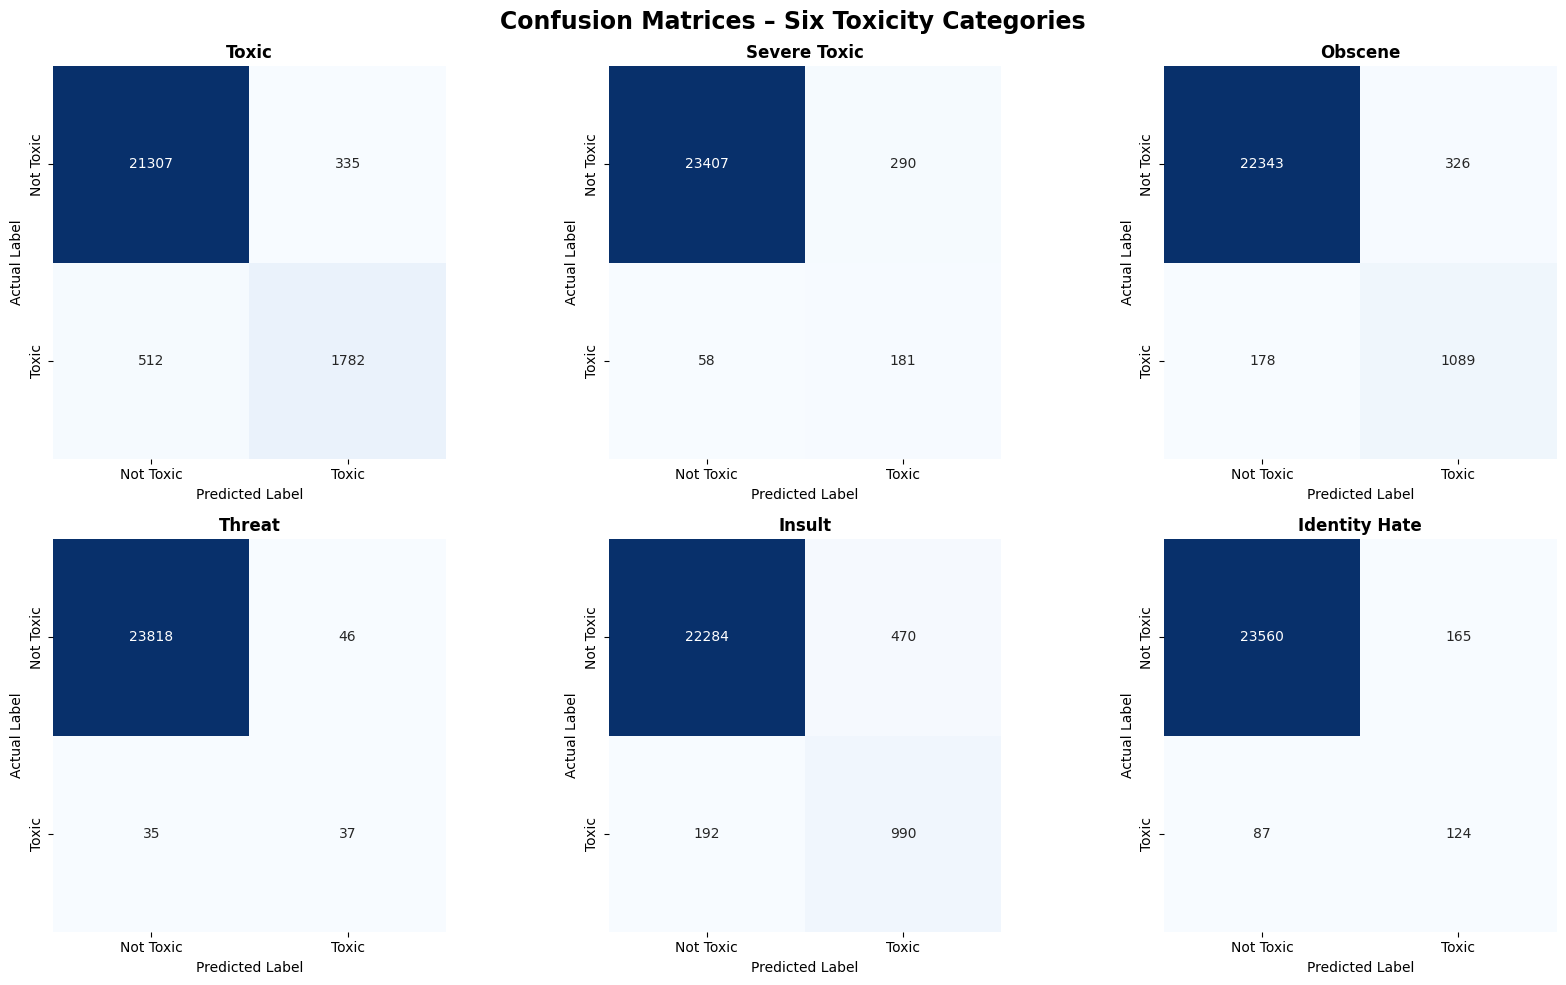

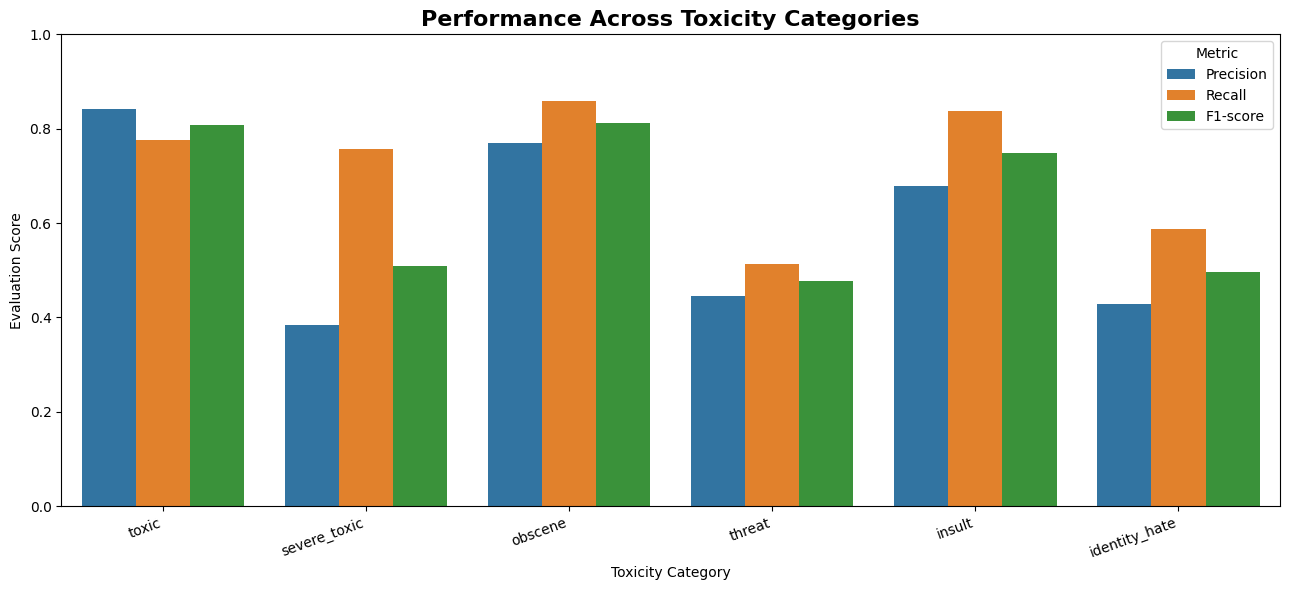

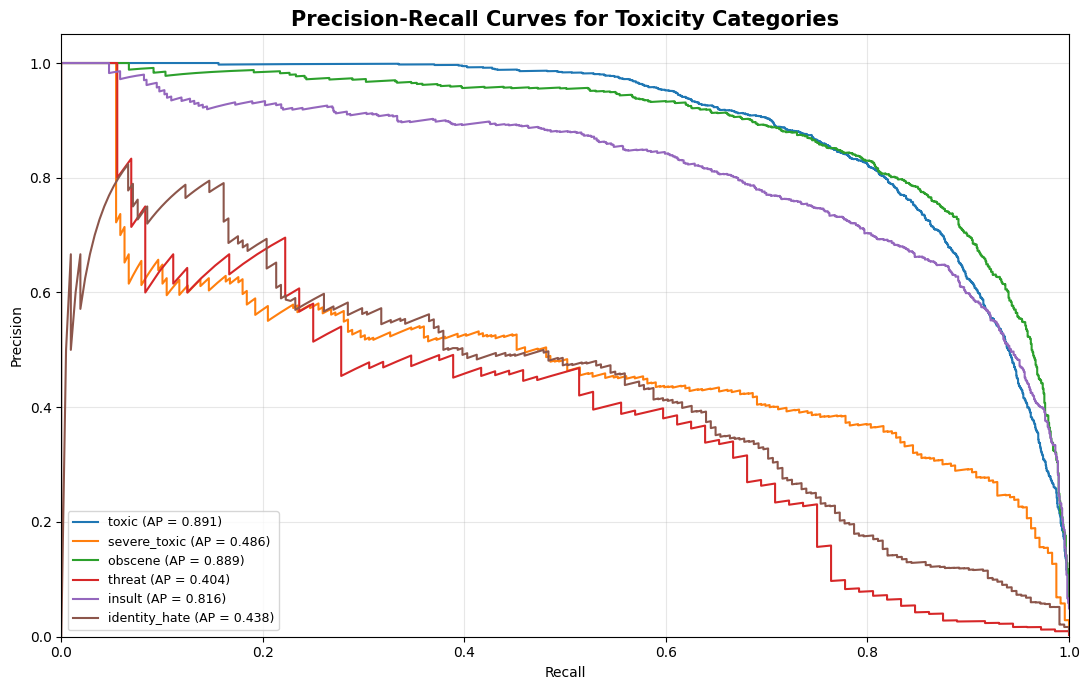


FINAL MODEL EVALUATION SUMMARY
Test samples              : 23,936
Micro F1-score            : 0.7573
Macro F1-score            : 0.6421
Weighted F1-score         : 0.7653
Subset accuracy           : 0.9176
Best detected category    : obscene
Most challenging category : threat
----------------------------------------------------------------------
Evaluation completed successfully.
The independent test set was used only for final evaluation.


In [14]:

# ================================================================
# SECTION 10 — COMPREHENSIVE MODEL EVALUATION
# ================================================================
#
# Objective:
# Evaluate the trained BiLSTM model using the independent test set.
#
# Evaluation includes:
# 1. Test-set predictions
# 2. Overall classification metrics
# 3. Per-category classification metrics
# 4. Detailed classification report
# 5. Confusion matrices
# 6. Category-wise performance visualization
# 7. Precision-Recall curves
# 8. Final evaluation summary
#
# IMPORTANT:
# This section performs evaluation only.
# It does not train or modify the trained model.
# ================================================================


# ------------------------------------------------
# 10.0 IMPORT REQUIRED LIBRARIES
# ------------------------------------------------

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    precision_recall_fscore_support,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve
)

print("Evaluation libraries imported successfully.")


# ------------------------------------------------
# 10.1 GENERATE TEST-SET PREDICTIONS
# ------------------------------------------------

model.eval()

all_test_probabilities = []
all_test_targets = []

with torch.no_grad():

    for token_ids, lengths, labels in test_loader:

        token_ids = token_ids.to(DEVICE)
        lengths = lengths.to(DEVICE)

        logits = model(token_ids, lengths)

        probabilities = torch.sigmoid(logits)

        all_test_probabilities.append(
            probabilities.cpu().numpy()
        )

        all_test_targets.append(
            labels.cpu().numpy()
        )

# Combine predictions from all test batches
y_test_prob = np.vstack(all_test_probabilities)

y_test = np.vstack(
    all_test_targets
).astype(int)


# Apply thresholds selected using validation data
optimal_thresholds = np.asarray(
    optimal_thresholds,
    dtype=float
)

if len(optimal_thresholds) != len(LABEL_COLUMNS):
    raise ValueError(
        "Number of thresholds does not match the number of labels."
    )

y_test_pred = (
    y_test_prob >= optimal_thresholds.reshape(1, -1)
).astype(int)


print("\nTEST SET PREDICTIONS GENERATED SUCCESSFULLY")
print("-" * 60)
print(f"Test samples          : {len(y_test):,}")
print(f"Number of categories  : {len(LABEL_COLUMNS)}")
print(f"Prediction shape      : {y_test_pred.shape}")


# ------------------------------------------------
# 10.2 CALCULATE OVERALL CLASSIFICATION METRICS
# ------------------------------------------------

overall_metrics = {

    "Micro Precision": precision_score(
        y_test,
        y_test_pred,
        average="micro",
        zero_division=0
    ),

    "Micro Recall": recall_score(
        y_test,
        y_test_pred,
        average="micro",
        zero_division=0
    ),

    "Micro F1": f1_score(
        y_test,
        y_test_pred,
        average="micro",
        zero_division=0
    ),

    "Macro Precision": precision_score(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    ),

    "Macro F1": f1_score(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    ),

    "Weighted Precision": precision_score(
        y_test,
        y_test_pred,
        average="weighted",
        zero_division=0
    ),

    "Weighted Recall": recall_score(
        y_test,
        y_test_pred,
        average="weighted",
        zero_division=0
    ),

    "Weighted F1": f1_score(
        y_test,
        y_test_pred,
        average="weighted",
        zero_division=0
    ),

    "Subset Accuracy": accuracy_score(
        y_test,
        y_test_pred
    )
}


overall_metrics_df = pd.DataFrame(
    list(overall_metrics.items()),
    columns=["Metric", "Score"]
)

print("\nOVERALL MODEL PERFORMANCE")

display(
    overall_metrics_df.style
    .format({"Score": "{:.4f}"})
    .background_gradient(
        subset=["Score"],
        cmap="YlGn"
    )
)


# ------------------------------------------------
# 10.3 CALCULATE PER-CATEGORY METRICS
# ------------------------------------------------

per_label_rows = []

for i, label in enumerate(LABEL_COLUMNS):

    # Calculate precision, recall and F1-score
    p, r, f1, _ = precision_recall_fscore_support(
        y_test[:, i],
        y_test_pred[:, i],
        average="binary",
        zero_division=0
    )

    # Calculate actual positive test examples directly
    support = int(
        np.sum(y_test[:, i] == 1)
    )

    # Calculate Average Precision using probabilities
    ap = average_precision_score(
        y_test[:, i],
        y_test_prob[:, i]
    )

    per_label_rows.append({

        "Label": label,

        "Precision": float(p),

        "Recall": float(r),

        "F1-score": float(f1),

        "Average precision": float(ap),

        "Support": support,

        "Threshold": float(optimal_thresholds[i])
    })


per_label_df = pd.DataFrame(per_label_rows)

print("\nPER-CATEGORY MODEL PERFORMANCE")

display(
    per_label_df.style
    .format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "Average precision": "{:.4f}",
        "Support": "{:,.0f}",
        "Threshold": "{:.3f}"
    })
    .background_gradient(
        subset=["F1-score"],
        cmap="YlGn"
    )
)


# ------------------------------------------------
# 10.4 DISPLAY DETAILED CLASSIFICATION REPORT
# ------------------------------------------------

print("\nDETAILED CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=LABEL_COLUMNS,
        zero_division=0,
        digits=4
    )
)


# ------------------------------------------------
# 10.5 GENERATE CONFUSION MATRICES
# ------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 10)
)

axes = axes.flatten()

for i, label in enumerate(LABEL_COLUMNS):

    cm = confusion_matrix(
        y_test[:, i],
        y_test_pred[:, i],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        xticklabels=["Not Toxic", "Toxic"],
        yticklabels=["Not Toxic", "Toxic"],
        ax=axes[i]
    )

    axes[i].set_title(
        label.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")


plt.suptitle(
    "Confusion Matrices – Six Toxicity Categories",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 10.6 VISUALIZE CATEGORY-WISE PERFORMANCE
# ------------------------------------------------

plot_metrics = per_label_df.melt(
    id_vars="Label",
    value_vars=[
        "Precision",
        "Recall",
        "F1-score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_metrics,
    x="Label",
    y="Score",
    hue="Metric"
)

plt.title(
    "Performance Across Toxicity Categories",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Toxicity Category")
plt.ylabel("Evaluation Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.legend(title="Metric")

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 10.7 PLOT PRECISION-RECALL CURVES
# ------------------------------------------------

plt.figure(figsize=(11, 7))

for i, label in enumerate(LABEL_COLUMNS):

    precision_values, recall_values, _ = precision_recall_curve(
        y_test[:, i],
        y_test_prob[:, i]
    )

    ap = per_label_df.loc[
        i,
        "Average precision"
    ]

    plt.plot(
        recall_values,
        precision_values,
        label=f"{label} (AP = {ap:.3f})"
    )


plt.title(
    "Precision-Recall Curves for Toxicity Categories",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.grid(alpha=0.3)

plt.legend(
    loc="best",
    fontsize=9
)

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 10.8 FINAL MODEL EVALUATION SUMMARY
# ------------------------------------------------

best_category = per_label_df.loc[
    per_label_df["F1-score"].idxmax(),
    "Label"
]

weakest_category = per_label_df.loc[
    per_label_df["F1-score"].idxmin(),
    "Label"
]

print("\n" + "=" * 70)
print("FINAL MODEL EVALUATION SUMMARY")
print("=" * 70)

print(f"Test samples              : {len(y_test):,}")

print(
    f"Micro F1-score            : "
    f"{overall_metrics['Micro F1']:.4f}"
)

print(
    f"Macro F1-score            : "
    f"{overall_metrics['Macro F1']:.4f}"
)

print(
    f"Weighted F1-score         : "
    f"{overall_metrics['Weighted F1']:.4f}"
)

print(
    f"Subset accuracy           : "
    f"{overall_metrics['Subset Accuracy']:.4f}"
)

print(f"Best detected category    : {best_category}")

print(f"Most challenging category : {weakest_category}")

print("-" * 70)

print(
    "Evaluation completed successfully."
)

print(
    "The independent test set was used only for final evaluation."
)

print("=" * 70)


## SECTION 11 — Optional Baseline Comparison (TF-IDF + Logistic Regression)

A capstone becomes stronger when the deep-learning model is compared with a simpler baseline. This optional experiment trains a one-vs-rest Logistic Regression classifier using TF-IDF word and bigram features. It uses the same training and validation data; thresholds are selected on validation data, and the held-out test set is used only for final comparison.

**Runtime note:** TF-IDF fitting can take several minutes and use additional RAM. Set `RUN_BASELINE = True` to execute it. The main BiLSTM project does not depend on this optional experiment.


In [25]:
# SECTION 11: OPTIONAL BASELINE COMPARISON
# TF-IDF + LOGISTIC REGRESSION

# Keep False if you do not want to train the additional baseline.
# This does not affect your already-trained BiLSTM model.

RUN_BASELINE = False

baseline_test_metrics = None

if RUN_BASELINE:

    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.multiclass import OneVsRestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import f1_score, accuracy_score

    print("Fitting TF-IDF features...")

    # 1. Convert comments into TF-IDF features
    tfidf = TfidfVectorizer(
        max_features=80000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        strip_accents='unicode'
    )

    X_train_tfidf = tfidf.fit_transform(X_train)
    X_val_tfidf = tfidf.transform(X_val)
    X_test_tfidf = tfidf.transform(X_test)

    # 2. Define and train Logistic Regression
    baseline = OneVsRestClassifier(
        LogisticRegression(
            max_iter=300,
            class_weight='balanced',
            solver='liblinear'
        ),
        n_jobs=-1
    )

    print("Training TF-IDF + Logistic Regression...")

    baseline.fit(X_train_tfidf, y_train)

    # 3. Select thresholds using validation data
    baseline_val_prob = baseline.predict_proba(X_val_tfidf)

    baseline_thresholds = []

    for label_index in range(len(LABEL_COLUMNS)):

        scores = [
            f1_score(
                y_val[:, label_index],
                (baseline_val_prob[:, label_index] >= threshold).astype(int),
                zero_division=0
            )
            for threshold in threshold_grid
        ]

        best_index = int(np.argmax(scores))
        baseline_thresholds.append(float(threshold_grid[best_index]))

    baseline_thresholds = np.asarray(baseline_thresholds)

    # 4. Evaluate baseline on the test set
    baseline_test_prob = baseline.predict_proba(X_test_tfidf)

    baseline_test_pred = (
        baseline_test_prob >= baseline_thresholds.reshape(1, -1)
    ).astype(int)

    baseline_test_metrics = {
        'Model': 'TF-IDF + Logistic Regression',

        'Micro F1': f1_score(
            y_test,
            baseline_test_pred,
            average='micro',
            zero_division=0
        ),

        'Macro F1': f1_score(
            y_test,
            baseline_test_pred,
            average='macro',
            zero_division=0
        ),

        'Weighted F1': f1_score(
            y_test,
            baseline_test_pred,
            average='weighted',
            zero_division=0
        ),

        'Subset Accuracy': accuracy_score(
            y_test,
            baseline_test_pred
        )
    }

    # 5. Compare BiLSTM and baseline
    comparison = pd.DataFrame([
        {
            'Model': 'BiLSTM',
            'Micro F1': overall_metrics['Micro F1'],
            'Macro F1': overall_metrics['Macro F1'],
            'Weighted F1': overall_metrics['Weighted F1'],
            'Subset Accuracy': overall_metrics['Subset Accuracy']
        },
        baseline_test_metrics
    ])

    print("\nMODEL COMPARISON")

    display(
        comparison.style.format({
            'Micro F1': '{:.4f}',
            'Macro F1': '{:.4f}',
            'Weighted F1': '{:.4f}',
            'Subset Accuracy': '{:.4f}'
        })
    )

else:

    print("Optional baseline comparison skipped.")
    print("The trained BiLSTM model remains your main model.")

Optional baseline comparison skipped.
The trained BiLSTM model remains your main model.


## SECTION 12 — Visualize Training, Performance and Error Patterns

Visualizations make the results easier to explain during a project review. The learning curves show whether training and validation loss diverge. The per-label chart highlights which toxicity categories are difficult. Confusion matrices show true positives, false positives, true negatives and false negatives for each label.

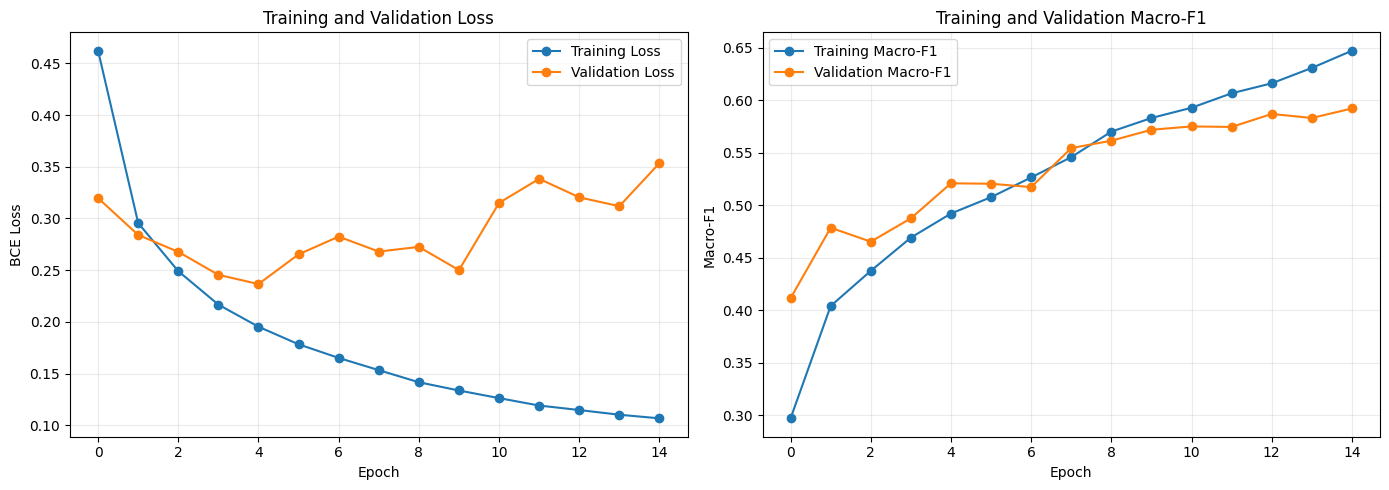

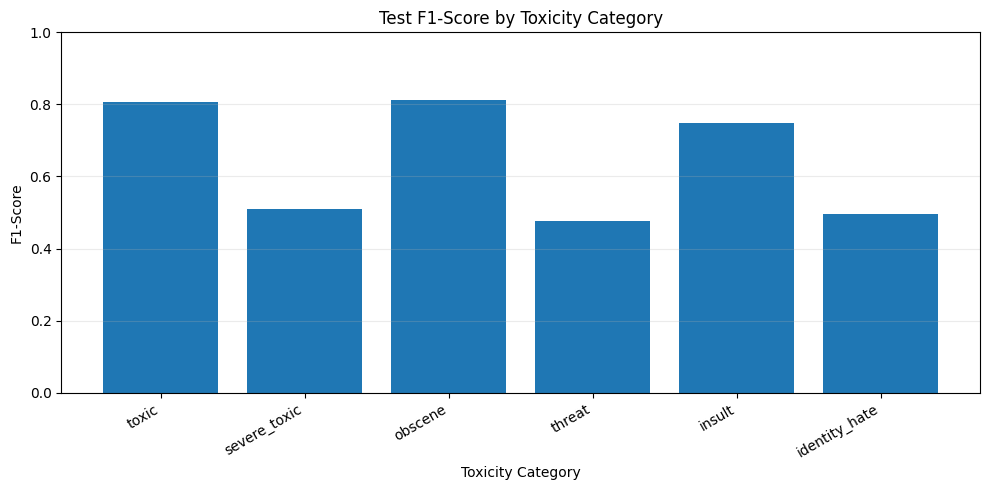

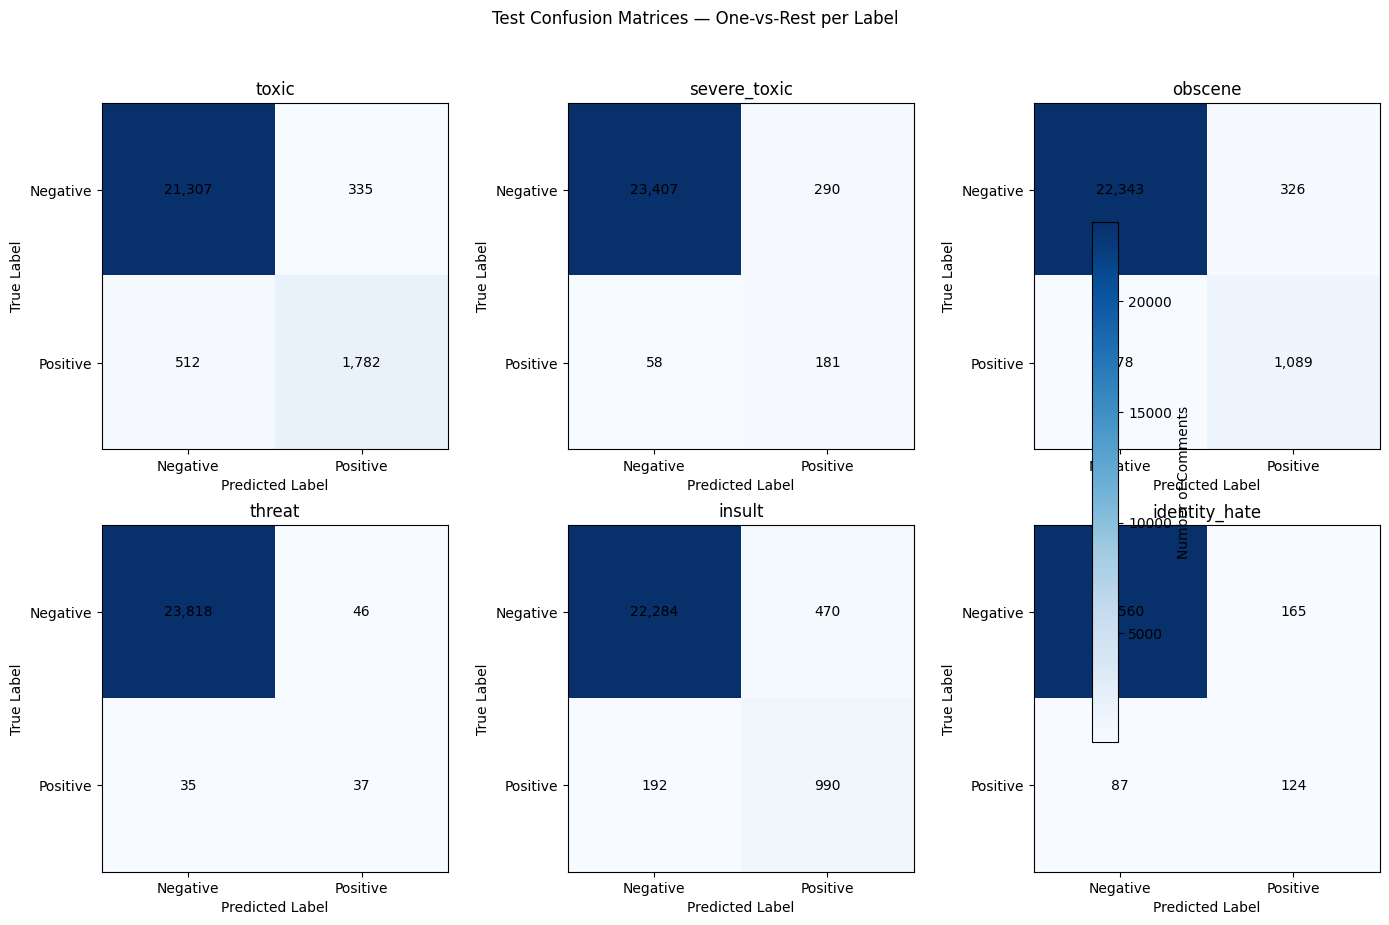

All performance visualizations generated successfully.


In [29]:
# SECTION 12: PERFORMANCE VISUALIZATIONS

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import multilabel_confusion_matrix

# --------------------------------------------------
# 1. TRAINING AND VALIDATION LEARNING CURVES
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history['train_loss'],
    marker='o',
    label='Training Loss'
)

axes[0].plot(
    history['val_loss'],
    marker='o',
    label='Validation Loss'
)

axes[0].set_title('Training and Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].legend()
axes[0].grid(alpha=0.25)


axes[1].plot(
    history['train_macro_f1'],
    marker='o',
    label='Training Macro-F1'
)

axes[1].plot(
    history['val_macro_f1'],
    marker='o',
    label='Validation Macro-F1'
)

axes[1].set_title('Training and Validation Macro-F1')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Macro-F1')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. PER-LABEL TEST F1-SCORE
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    per_label_df['Label'],
    per_label_df['F1-score']
)

plt.title('Test F1-Score by Toxicity Category')
plt.xlabel('Toxicity Category')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. CONFUSION MATRICES
# --------------------------------------------------

conf_matrices = multilabel_confusion_matrix(
    y_test,
    y_test_pred
)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for i, ax in enumerate(axes.flat):

    cm = conf_matrices[i]

    im = ax.imshow(cm, cmap='Blues')

    ax.set_title(LABEL_COLUMNS[i])
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Negative', 'Positive'])

    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Negative', 'Positive'])

    for (row, col), value in np.ndenumerate(cm):

        ax.text(
            col,
            row,
            f'{value:,}',
            ha='center',
            va='center'
        )

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.75,
    label='Number of Comments'
)

fig.suptitle(
    'Test Confusion Matrices — One-vs-Rest per Label',
    y=1.02
)

plt.tight_layout()
plt.show()

print("All performance visualizations generated successfully.")

## SECTION 12.1 — Error Analysis: False Positives and False Negatives

In [26]:
# SECTION 12.1: ERROR ANALYSIS
# Inspect False Positives and False Negatives

import numpy as np
import pandas as pd
from IPython.display import display

error_rows = []

for label_index, label_name in enumerate(LABEL_COLUMNS):

    # Identify false-positive examples
    false_positive_indices = np.where(
        (y_test_pred[:, label_index] == 1) &
        (y_test[:, label_index] == 0)
    )[0][:3]

    # Identify false-negative examples
    false_negative_indices = np.where(
        (y_test_pred[:, label_index] == 0) &
        (y_test[:, label_index] == 1)
    )[0][:3]

    # Store false positives
    for idx in false_positive_indices:

        error_rows.append({
            'Toxicity Category': label_name,
            'Error Type': 'False Positive',
            'Comment': str(X_test[idx])[:350],
            'Predicted Probability': float(
                y_test_prob[idx, label_index]
            )
        })

    # Store false negatives
    for idx in false_negative_indices:

        error_rows.append({
            'Toxicity Category': label_name,
            'Error Type': 'False Negative',
            'Comment': str(X_test[idx])[:350],
            'Predicted Probability': float(
                y_test_prob[idx, label_index]
            )
        })


# Create error-analysis DataFrame
error_examples = pd.DataFrame(error_rows)

print("=" * 75)
print("ERROR ANALYSIS: FALSE POSITIVES AND FALSE NEGATIVES")
print("=" * 75)

if not error_examples.empty:

    display(
        error_examples.style.format({
            'Predicted Probability': '{:.2%}'
        })
    )

    print("\nInterpretation:")
    print("False Positive: A non-toxic label was incorrectly detected.")
    print("False Negative: A toxic label was missed by the model.")

else:

    print("No false-positive or false-negative examples were collected.")

print("=" * 75)

ERROR ANALYSIS: FALSE POSITIVES AND FALSE NEGATIVES


,Toxicity Category,Error Type,Comment,Predicted Probability
0,toxic,False Positive,hate is my topic is hate if you hate a person means you like that person your hate can turn into your love,97.71%
1,toxic,False Positive,speaking without knowing what i'm talking about ok how 'bout this the original comment i made about everlast's entry constantly being vandalized by eminem fans was written a month ago before your dumb ass got involved with the site the feud started with the dilated peoples track that's why i believed that the verse everlast contributed should be in,97.59%
2,toxic,False Positive,typical troll most of the bio which was not written by me is about the various martial arts i have encountered never said i was a master of all of them one paragraph at the top mentions three of my thirty books i figure that's pretty humble lol only two references to getting some publicity overseas nothing here but you read that as boasting take so,94.70%
3,toxic,False Negative,why can't you believe how fat artie is did you see him on his recent appearence on the tonight show with jay leno he looks absolutely awful if i had to put money on it i'd say that artie lange is a can't miss candidate for the 2007 dead pool kindly keep your malicious fingers off of my above comment everytime you remove it i will repost it,51.87%
4,toxic,False Negative,unblock me or i'll get my lawyers on to you for blocking my constitutional right to free speech,37.48%
5,toxic,False Negative,add mobile porn as additional wp also link,0.00%
6,severe_toxic,False Positive,how about this go fuck yourself,91.63%
7,severe_toxic,False Positive,lol dumb arabs and their you cant show my god heres a bomb because i have sand in my vagina fucking towelheads,91.80%
8,severe_toxic,False Positive,demonte morton u bastard stop deletin' my shit u white trash cracker muthafucker fuck u u racist bitch i hope u die,93.15%
9,severe_toxic,False Negative,you know i was thinking nobody really attacked me before i revealed my age here after i announced that i was 14 i was subject to a constant storm of harassment and abuse the same thing goes for when i was on the sandbox when i was 11 before people knew my age they didn't care after i told them my age they hated me it's just so amusing how the idiot,0.24%



Interpretation:
False Positive: A non-toxic label was incorrectly detected.
False Negative: A toxic label was missed by the model.


## SECTION 13 — Save the Trained Model and Project Artifacts

In [27]:
# SECTION 13: SAVE THE TRAINED MODEL AND PROJECT ARTIFACTS

import os
import json
import torch
import numpy as np
import pandas as pd


# --------------------------------------------------
# 1. CREATE OUTPUT DIRECTORY
# --------------------------------------------------

OUTPUT_DIR = '/content/drive/MyDrive/DL_cyber_data/model_output'

os.makedirs(OUTPUT_DIR, exist_ok=True)


# --------------------------------------------------
# 2. DEFINE OUTPUT FILE PATHS
# --------------------------------------------------

MODEL_FILE = os.path.join(
    OUTPUT_DIR,
    'bilstm_toxic_comment_model.pt'
)

VOCAB_FILE = os.path.join(
    OUTPUT_DIR,
    'vocabulary.json'
)

CONFIG_FILE = os.path.join(
    OUTPUT_DIR,
    'model_config.json'
)

METRICS_FILE = os.path.join(
    OUTPUT_DIR,
    'test_metrics.csv'
)


# --------------------------------------------------
# 3. PREPARE MODEL CHECKPOINT
# --------------------------------------------------

checkpoint = {
    'model_state_dict': model.state_dict(),

    'vocab_size': len(vocab),

    'embedding_dim': EMBEDDING_DIM,

    'hidden_dim': HIDDEN_DIM,

    'output_dim': NUM_LABELS,

    'num_layers': NUM_LAYERS,

    'dropout': DROPOUT,

    'max_length': MAX_LENGTH,

    'label_columns': list(LABEL_COLUMNS),

    'thresholds': np.asarray(
        optimal_thresholds,
        dtype=float
    ).tolist()
}


# --------------------------------------------------
# 4. SAVE TRAINED MODEL
# --------------------------------------------------

torch.save(checkpoint, MODEL_FILE)

print("Trained model saved successfully.")


# --------------------------------------------------
# 5. SAVE VOCABULARY
# --------------------------------------------------

with open(VOCAB_FILE, 'w', encoding='utf-8') as file:

    json.dump(
        vocab,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Vocabulary saved successfully.")


# --------------------------------------------------
# 6. PREPARE MODEL CONFIGURATION
# --------------------------------------------------

config = {
    'model_name': 'Bidirectional LSTM for Toxic Comment Detection',

    'model_type': 'Multi-label Text Classification',

    'label_columns': list(LABEL_COLUMNS),

    'max_length': int(MAX_LENGTH),

    'vocab_size': int(len(vocab)),

    'embedding_dim': int(EMBEDDING_DIM),

    'hidden_dim': int(HIDDEN_DIM),

    'num_layers': int(NUM_LAYERS),

    'dropout': float(DROPOUT),

    'thresholds': np.asarray(
        optimal_thresholds,
        dtype=float
    ).tolist(),

    'cleaning': (
        'Lowercase; replace URLs and emails; '
        'retain alphanumeric characters and apostrophes.'
    )
}


# --------------------------------------------------
# 7. SAVE MODEL CONFIGURATION
# --------------------------------------------------

with open(CONFIG_FILE, 'w', encoding='utf-8') as file:

    json.dump(
        config,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Model configuration saved successfully.")


# --------------------------------------------------
# 8. CREATE AND SAVE TEST METRICS
# --------------------------------------------------

# Overall evaluation metrics from Section 10
overall_export = overall_metrics_df.copy()

overall_export.insert(
    0,
    'Category',
    'Overall'
)

# Individual toxicity category metrics from Section 10
per_label_export = per_label_df.copy()

per_label_export.insert(
    0,
    'Category',
    'Per-label'
)

# Combine both tables
metrics_summary = pd.concat(
    [overall_export, per_label_export],
    ignore_index=True,
    sort=False
)

# Save combined evaluation metrics
metrics_summary.to_csv(
    METRICS_FILE,
    index=False
)

print("Test evaluation metrics saved successfully.")


# --------------------------------------------------
# 9. VERIFY SAVED ARTIFACTS
# --------------------------------------------------

saved_files = [
    MODEL_FILE,
    VOCAB_FILE,
    CONFIG_FILE,
    METRICS_FILE
]

print("\n")
print("=" * 70)
print("PROJECT ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 70)

for file_path in saved_files:

    if os.path.exists(file_path):

        file_size = os.path.getsize(file_path) / 1024

        print(
            f"✓ {os.path.basename(file_path)} "
            f"({file_size:.2f} KB)"
        )

    else:

        raise FileNotFoundError(
            f"File was not saved: {file_path}"
        )

print("=" * 70)
print("All project artifacts are ready for inference.")
print("=" * 70)

Trained model saved successfully.
Vocabulary saved successfully.
Model configuration saved successfully.
Test evaluation metrics saved successfully.


PROJECT ARTIFACTS SAVED SUCCESSFULLY
✓ bilstm_toxic_comment_model.pt (22005.71 KB)
✓ vocabulary.json (1072.56 KB)
✓ model_config.json (0.69 KB)
✓ test_metrics.csv (1.26 KB)
All project artifacts are ready for inference.


### Section 13 notes — Saved model and inference requirements

Save everything required for inference: model weights, architecture settings, vocabulary, label names, maximum sequence length and validation-selected thresholds. Saving these together prevents preprocessing or label-order mismatches when the model is used later.

## SECTION 14 — Load the Saved Model and Predict New Comments

In [28]:
# SECTION 14: LOAD MODEL AND PERFORM TOXICITY PREDICTION

import os
import json
import torch
import numpy as np
import pandas as pd
from IPython.display import display


# --------------------------------------------------
# 1. VERIFY SAVED FILES
# --------------------------------------------------

required_files = [
    MODEL_FILE,
    VOCAB_FILE,
    CONFIG_FILE,
    METRICS_FILE
]

for file_path in required_files:

    if not os.path.exists(file_path):

        raise FileNotFoundError(
            f"Required file not found: {file_path}"
        )

print("All saved artifacts are available.")


# --------------------------------------------------
# 2. LOAD MODEL CHECKPOINT
# --------------------------------------------------

loaded_checkpoint = torch.load(
    MODEL_FILE,
    map_location=DEVICE,
    weights_only=True
)

print("Model checkpoint loaded successfully.")


# --------------------------------------------------
# 3. LOAD VOCABULARY
# --------------------------------------------------

with open(VOCAB_FILE, 'r', encoding='utf-8') as file:

    loaded_vocab = json.load(file)

print(f"Vocabulary loaded: {len(loaded_vocab):,} tokens")


# --------------------------------------------------
# 4. LOAD MODEL CONFIGURATION
# --------------------------------------------------

with open(CONFIG_FILE, 'r', encoding='utf-8') as file:

    loaded_config = json.load(file)

INFERENCE_LABELS = loaded_checkpoint['label_columns']

INFERENCE_THRESHOLDS = np.asarray(
    loaded_checkpoint['thresholds'],
    dtype=np.float32
).reshape(-1)

INFERENCE_MAX_LENGTH = int(
    loaded_checkpoint['max_length']
)


# --------------------------------------------------
# 5. VERIFY MODEL CONFIGURATION
# --------------------------------------------------

if len(INFERENCE_LABELS) != len(INFERENCE_THRESHOLDS):

    raise ValueError(
        "Number of labels and thresholds do not match."
    )

if len(INFERENCE_LABELS) != NUM_LABELS:

    raise ValueError(
        "Saved output dimension does not match the project labels."
    )

if len(loaded_vocab) != loaded_checkpoint['vocab_size']:

    raise ValueError(
        "Saved vocabulary size does not match the model checkpoint."
    )

print("Model configuration verified successfully.")

print("Labels:", INFERENCE_LABELS)

print("Maximum sequence length:", INFERENCE_MAX_LENGTH)


# --------------------------------------------------
# 6. RECONSTRUCT THE BiLSTM MODEL
# --------------------------------------------------

inference_model = BiLSTMClassifier(
    vocab_size=loaded_checkpoint['vocab_size'],
    embedding_dim=loaded_checkpoint['embedding_dim'],
    hidden_dim=loaded_checkpoint['hidden_dim'],
    output_dim=loaded_checkpoint['output_dim'],
    num_layers=loaded_checkpoint['num_layers'],
    dropout=loaded_checkpoint['dropout']
).to(DEVICE)

inference_model.load_state_dict(
    loaded_checkpoint['model_state_dict']
)

inference_model.eval()

print("Inference model reconstructed successfully.")


# --------------------------------------------------
# 7. ENCODE NEW COMMENTS
# --------------------------------------------------

def encode_new_comment(comment):

    if not isinstance(comment, str):

        raise TypeError(
            "Input comment must be a string."
        )

    cleaned = clean_text(comment)

    tokens = cleaned.split()[:INFERENCE_MAX_LENGTH]

    # Convert tokens into vocabulary indices
    token_ids = [
        loaded_vocab.get(token, 1)
        for token in tokens
    ]

    # Handle empty comments
    if not token_ids:

        token_ids = [1]

    length = len(token_ids)

    # Add padding
    token_ids += [
        0
    ] * (INFERENCE_MAX_LENGTH - length)

    token_tensor = torch.tensor(
        [token_ids],
        dtype=torch.long
    )

    length_tensor = torch.tensor(
        [length],
        dtype=torch.long
    )

    return token_tensor, length_tensor


# --------------------------------------------------
# 8. DEFINE TOXICITY PREDICTION FUNCTION
# --------------------------------------------------

@torch.no_grad()
def predict_toxicity(comment):

    token_ids, lengths = encode_new_comment(comment)

    token_ids = token_ids.to(DEVICE)

    lengths = lengths.to(DEVICE)

    logits = inference_model(
        token_ids,
        lengths
    )

    probabilities = torch.sigmoid(
        logits
    )[0].cpu().numpy()

    # Apply validation-selected thresholds
    predictions = (
        probabilities >= INFERENCE_THRESHOLDS
    )

    prediction_table = pd.DataFrame({

        'Toxicity Category': INFERENCE_LABELS,

        'Probability': probabilities,

        'Threshold': INFERENCE_THRESHOLDS,

        'Prediction': np.where(
            predictions,
            'Detected',
            'Not Detected'
        )
    })

    overall_result = (
        'Potentially Toxic'
        if predictions.any()
        else 'No Toxicity Label Detected'
    )

    prediction_table = prediction_table.sort_values(
        by='Probability',
        ascending=False
    ).reset_index(drop=True)

    return overall_result, prediction_table


# --------------------------------------------------
# 9. TEST WITH SAMPLE COMMENTS
# --------------------------------------------------

DEMO_COMMENTS = [

    'Have a nice day! I hope everything goes well.',

    'You are an idiot and nobody likes you.',

    'I disagree with your opinion, but I respect your point of view.'

]


# --------------------------------------------------
# 10. DISPLAY PREDICTION RESULTS
# --------------------------------------------------

print("\n")

print("=" * 75)

print("TOXIC COMMENT DETECTION - INFERENCE RESULTS")

print("=" * 75)

for index, comment in enumerate(DEMO_COMMENTS, start=1):

    overall_result, prediction_table = predict_toxicity(
        comment
    )

    print(f"\nExample {index}")

    print("-" * 75)

    print("Comment:", comment)

    print("Overall Result:", overall_result)

    display(
        prediction_table.style.format({

            'Probability': '{:.2%}',

            'Threshold': '{:.2%}'

        }).hide(axis='index')
    )

print("=" * 75)

print("INFERENCE TESTING COMPLETED SUCCESSFULLY")

print("=" * 75)

All saved artifacts are available.
Model checkpoint loaded successfully.
Vocabulary loaded: 50,000 tokens
Model configuration verified successfully.
Labels: ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
Maximum sequence length: 200
Inference model reconstructed successfully.


TOXIC COMMENT DETECTION - INFERENCE RESULTS

Example 1
---------------------------------------------------------------------------
Comment: Have a nice day! I hope everything goes well.
Overall Result: No Toxicity Label Detected


Toxicity Category,Probability,Threshold,Prediction
toxic,0.35%,88.00%,Not Detected
obscene,0.00%,90.00%,Not Detected
insult,0.00%,88.00%,Not Detected
threat,0.00%,78.00%,Not Detected
identity_hate,0.00%,88.00%,Not Detected
severe_toxic,0.00%,86.00%,Not Detected



Example 2
---------------------------------------------------------------------------
Comment: You are an idiot and nobody likes you.
Overall Result: Potentially Toxic


Toxicity Category,Probability,Threshold,Prediction
toxic,99.96%,88.00%,Detected
insult,99.89%,88.00%,Detected
obscene,98.27%,90.00%,Detected
identity_hate,16.87%,88.00%,Not Detected
severe_toxic,5.63%,86.00%,Not Detected
threat,0.06%,78.00%,Not Detected



Example 3
---------------------------------------------------------------------------
Comment: I disagree with your opinion, but I respect your point of view.
Overall Result: No Toxicity Label Detected


Toxicity Category,Probability,Threshold,Prediction
toxic,0.08%,88.00%,Not Detected
obscene,0.00%,90.00%,Not Detected
threat,0.00%,78.00%,Not Detected
insult,0.00%,88.00%,Not Detected
identity_hate,0.00%,88.00%,Not Detected
severe_toxic,0.00%,86.00%,Not Detected


INFERENCE TESTING COMPLETED SUCCESSFULLY


## SECTION 15 — Conclusion, Limitations and Future Scope

### Conclusion

### Conclusion

This project demonstrates a multi-label NLP pipeline for detecting six categories of toxic comments. It combines text normalization, training-only vocabulary construction, a Bidirectional LSTM, imbalance-aware loss, validation-based early stopping and threshold selection, and a final held-out test evaluation.

### Limitations

- The model learns patterns from the Jigsaw dataset and may not generalize to every platform, language, community or time period.
- Toxicity is context-dependent. Sarcasm, quotation, reclaimed language and conversational history may be misunderstood.
- Class weighting and threshold selection improve the handling of rare labels but do not eliminate bias or false predictions.
- Predicted scores are model outputs and should not be treated as calibrated probabilities or as the sole basis for moderation decisions.

### Future scope

- Compare BiLSTM with TF-IDF + Logistic Regression and transformer models such as DistilBERT.
- Add multilingual support and evaluate on additional datasets.
- Build a Streamlit interface with single-comment and CSV batch prediction.
- Add explainability, human review and feedback-based monitoring.

### Final reproducibility checklist

- [ ] Run all cells from Section 1 to Section 12 in order.
- [ ] Confirm the dataset path and verify the dataset columns.
- [ ] Record the actual test metrics generated by your run.
- [ ] Review false positives and false negatives.
- [ ] Confirm the saved model and vocabulary files exist in Google Drive.
- [ ] Do not report validation metrics as test metrics.

**End of project notebook.**